# Bank Term Deposit Subscription Prediction

### A Comparative Machine Learning Study

**Course:** DATA 3461 — Machine Learning  
**Dataset:** UCI Bank Marketing Dataset  
**Task:** Binary Classification

---

## Project Overview

This project investigates the use of supervised machine learning
to predict whether a bank customer will subscribe to a term deposit.

Three classification algorithms are evaluated:

- Logistic Regression
- Random Forest
- Gradient Boosting

A majority-class baseline is included to establish a reference
for model performance.

**Primary evaluation metrics:** Precision, Recall, F1-score,
and Average Precision (PR-AUC summary).

> **Research Objective:** Identify potential term deposit subscribers
> using customer and campaign information available before a
> marketing call takes place.

In [1]:
import sys
print(sys.executable)

/Users/sunaihra_zeb/Desktop/^.^/uta/ds/3461/project/DATA-3461-Bank-Term-Deposit-Prediction/.venv/bin/python


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/bank-additional-full.csv", sep=";")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


---

## 2. Exploratory Data Analysis

### 2.1 Dataset Overview

The dataset contains **41,188 customer records** and **21 columns**,
including the target variable `y`.

The analysis examines:

- Dataset dimensions and feature types
- Missing and unknown values
- Duplicate observations
- Target class distribution
- Customer demographic characteristics
- Subscription rates across job categories

### 2.2 Class Imbalance

Only approximately **11.27%** of customers subscribed to a term
deposit.

> **Key Finding:** The dataset is highly imbalanced. Accuracy alone
> is insufficient for evaluating classification performance because
> a model predicting only the majority class can achieve high accuracy
> without identifying any subscribers.

In [4]:
# Display column names and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  str    
 2   marital         41188 non-null  str    
 3   education       41188 non-null  str    
 4   default         41188 non-null  str    
 5   housing         41188 non-null  str    
 6   loan            41188 non-null  str    
 7   contact         41188 non-null  str    
 8   month           41188 non-null  str    
 9   day_of_week     41188 non-null  str    
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  str    
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null  float64
 1

In [5]:
# Check for missing values
print("Missing values per column:")
print(df.isnull().sum())

# Check for 'unknown' values
print("\nUnknown values per column:")
print((df == "unknown").sum())

Missing values per column:
age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

Unknown values per column:
age                  0
job                330
marital             80
education         1731
default           8597
housing            990
loan               990
contact              0
month                0
day_of_week          0
duration             0
campaign             0
pdays                0
previous             0
poutcome             0
emp.var.rate         0
cons.price.idx       0
cons.conf.idx        0
euribor3m            0
nr.employed          0
y                    0
dtype: int64


In [6]:
# Check for duplicate rows
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 12


In [7]:
# Count customers who subscribed vs. did not subscribe
print(df["y"].value_counts())

# Calculate percentages
print("\nClass distribution (%):")
print(df["y"].value_counts(normalize=True) * 100)

y
no     36548
yes     4640
Name: count, dtype: int64

Class distribution (%):
y
no     88.734583
yes    11.265417
Name: proportion, dtype: float64


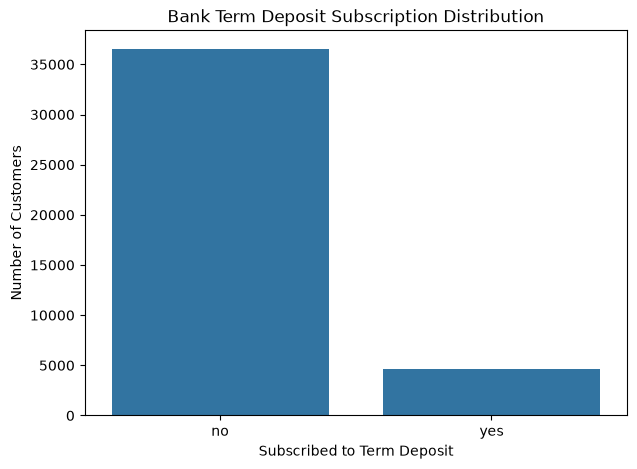

In [8]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x="y",
    order=["no", "yes"]
)

plt.title("Bank Term Deposit Subscription Distribution")
plt.xlabel("Subscribed to Term Deposit")
plt.ylabel("Number of Customers")

plt.show()

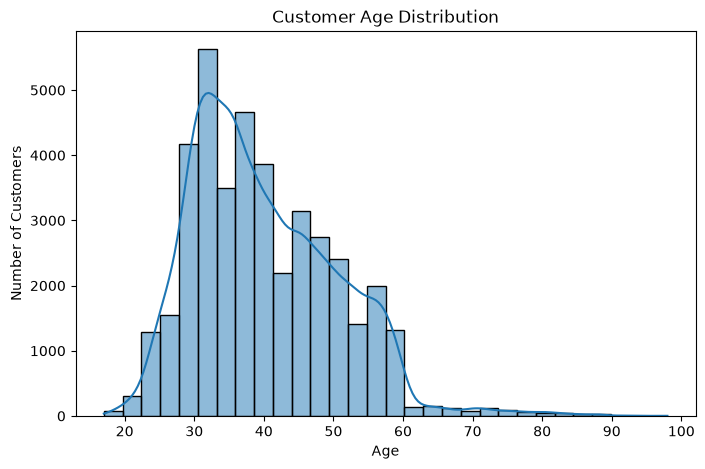

In [9]:
plt.figure(figsize=(8, 5))

sns.histplot(
    data=df,
    x="age",
    bins=30,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

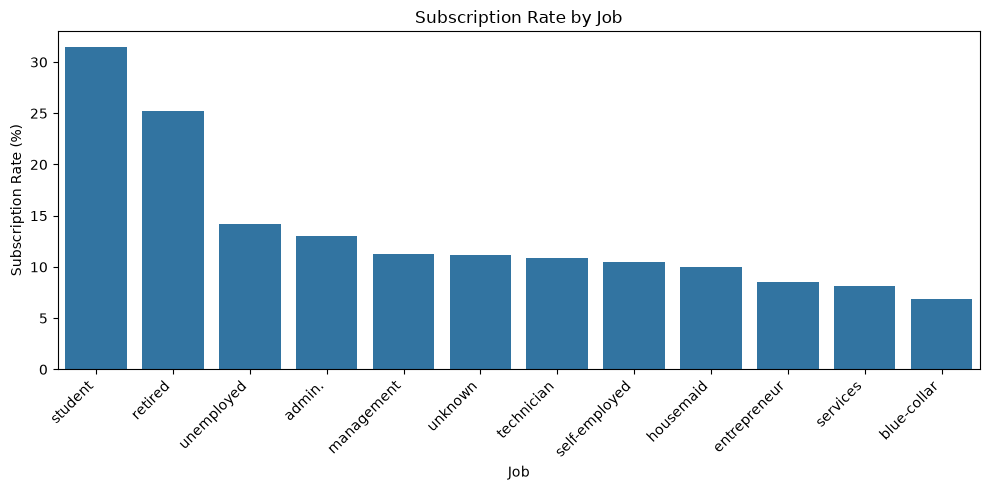

In [10]:
job_rates = (
    df.groupby("job")["y"]
    .apply(lambda x: (x == "yes").mean() * 100)
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=job_rates.index,
    y=job_rates.values
)

plt.title("Subscription Rate by Job")
plt.xlabel("Job")
plt.ylabel("Subscription Rate (%)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [11]:
unknown_counts = (df == "unknown").sum()

print(unknown_counts[unknown_counts > 0].to_string())

job           330
marital        80
education    1731
default      8597
housing       990
loan          990


In [12]:
# Summary statistics for numerical features
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,41188.0,40.024060,10.421250,17.000,32.000,38.000,47.000,98.000
duration,41188.0,258.285010,259.279249,0.000,102.000,180.000,319.000,4918.000
campaign,41188.0,2.567593,2.770014,1.000,1.000,2.000,3.000,56.000
pdays,41188.0,962.475454,186.910907,0.000,999.000,999.000,999.000,999.000
previous,41188.0,0.172963,0.494901,0.000,0.000,0.000,0.000,7.000
emp.var.rate,41188.0,0.081886,1.570960,-3.400,-1.800,1.100,1.400,1.400
cons.price.idx,41188.0,93.575664,0.578840,92.201,93.075,93.749,93.994,94.767
cons.conf.idx,41188.0,-40.502600,4.628198,-50.800,-42.700,-41.800,-36.400,-26.900
euribor3m,41188.0,3.621291,1.734447,0.634,1.344,4.857,4.961,5.045
nr.employed,41188.0,5167.035911,72.251528,4963.600,5099.100,5191.000,5228.100,5228.100


---

## 3. Data Cleaning and Preprocessing

### 3.1 Data Cleaning

The following preprocessing steps were performed:

1. Removed 12 duplicate observations.
2. Converted the target variable into binary labels (`no = 0`, `yes = 1`).
3. Identified categorical features containing `unknown` values.
4. Excluded the `duration` feature to prevent information leakage.

**Final dataset:** 41,176 records and 19 predictive features.

### 3.2 Training, Validation, and Test Splits

The dataset was divided using stratified sampling:

| Dataset | Records | Proportion |
|---|---:|---:|
| Training | 28,823 | 70% |
| Validation | 6,176 | 15% |
| Testing | 6,177 | 15% |

Stratification preserves the proportion of subscribers across splits.

### 3.3 Feature Transformation

- **Categorical features:** One-hot encoding
- **Numerical features:** Standard scaling
- **Total transformed features:** 62

All transformations were incorporated into scikit-learn preprocessing
pipelines to prevent training-validation leakage.

In [13]:
# Create a copy to preserve the original dataset
df_clean = df.copy()

# Remove duplicate records
df_clean = df_clean.drop_duplicates().reset_index(drop=True)

print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Duplicates remaining:", df_clean.duplicated().sum())

Original dataset: (41188, 21)
Cleaned dataset: (41176, 21)
Duplicates remaining: 0


In [14]:
# Convert target variable to binary values
df_clean["y"] = df_clean["y"].map({
    "no": 0,
    "yes": 1
})

print(df_clean["y"].value_counts())

y
0    36537
1     4639
Name: count, dtype: int64


In [15]:
# Separate features and target
X = df_clean.drop(columns=["y", "duration"])
y = df_clean["y"]

print("Feature matrix:", X.shape)
print("Target vector:", y.shape)
print("Remaining features:", X.columns.tolist())

Feature matrix: (41176, 19)
Target vector: (41176,)
Remaining features: ['age', 'job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'campaign', 'pdays', 'previous', 'poutcome', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']


In [16]:
from sklearn.model_selection import train_test_split

# Split into 70% training and 30% temporary data
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split temporary data into 15% validation and 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nPositive class percentages:")
print("Training:", round(y_train.mean() * 100, 2))
print("Validation:", round(y_val.mean() * 100, 2))
print("Testing:", round(y_test.mean() * 100, 2))

Training: (28823, 19)
Validation: (6176, 19)
Testing: (6177, 19)

Positive class percentages:
Training: 11.27
Validation: 11.27
Testing: 11.27


In [17]:
# Identify categorical and numerical columns
categorical_features = X_train.select_dtypes(
    include=["object", "str", "category"]
).columns.tolist()

numerical_features = X_train.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Categorical features:", categorical_features)
print("\nNumerical features:", numerical_features)

print("\nNumber of categorical features:", len(categorical_features))
print("Number of numerical features:", len(numerical_features))

Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']

Numerical features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']

Number of categorical features: 10
Number of numerical features: 9


In [18]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both transformations
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [19]:
# Fit preprocessing on training data only
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the same transformations to validation and test data
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Validation shape:", X_val_processed.shape)
print("Testing shape:", X_test_processed.shape)

print("\nTotal processed features:",
      X_train_processed.shape[1])

Training shape: (28823, 62)
Validation shape: (6176, 62)
Testing shape: (6177, 62)

Total processed features: 62


---

## 4. Model Training and Evaluation

Four classification approaches were evaluated.

### 4.1 Majority-Class Baseline

A baseline classifier predicts the majority class (`no`) for
every observation.

This establishes a reference point for assessing whether more
complex models provide meaningful improvements.

### 4.2 Logistic Regression

Logistic Regression provides a linear probabilistic classification
model.

Class weighting is used to address the imbalance between subscribers
and non-subscribers.

### 4.3 Random Forest

Random Forest combines multiple decision trees to capture
nonlinear relationships between customer characteristics
and subscription outcomes.

### 4.4 Gradient Boosting

Gradient Boosting sequentially builds decision trees to improve
predictive performance.

The model is evaluated using precision, recall, F1-score,
and average precision.

In [20]:
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix
)

# Train majority-class baseline
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)

# Predict on validation data
y_val_pred = baseline.predict(X_val)
y_val_prob = baseline.predict_proba(X_val)[:, 1]

# Evaluate baseline
print("Baseline Model Results")
print("----------------------")
print("Accuracy:", round(accuracy_score(y_val, y_val_pred), 4))
print("Precision:", round(precision_score(y_val, y_val_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, y_val_pred), 4))
print("F1-score:", round(f1_score(y_val, y_val_pred), 4))
print("PR-AUC:", round(average_precision_score(y_val, y_val_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, y_val_pred))

Baseline Model Results
----------------------
Accuracy: 0.8873
Precision: 0.0
Recall: 0.0
F1-score: 0.0
PR-AUC: 0.1127

Confusion Matrix:
[[5480    0]
 [ 696    0]]


In [21]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

# Create pipeline with preprocessing and model
logistic_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

# Train on training data
logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully!")

Logistic Regression trained successfully!


In [22]:
# Predict on validation data
lr_pred = logistic_model.predict(X_val)
lr_prob = logistic_model.predict_proba(X_val)[:, 1]

# Calculate metrics
print("Logistic Regression Results")
print("---------------------------")
print("Accuracy:", round(accuracy_score(y_val, lr_pred), 4))
print("Precision:", round(precision_score(y_val, lr_pred), 4))
print("Recall:", round(recall_score(y_val, lr_pred), 4))
print("F1-score:", round(f1_score(y_val, lr_pred), 4))
print("PR-AUC:", round(average_precision_score(y_val, lr_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, lr_pred))

Logistic Regression Results
---------------------------
Accuracy: 0.8251
Precision: 0.3491
Recall: 0.6379
F1-score: 0.4512
PR-AUC: 0.443

Confusion Matrix:
[[4652  828]
 [ 252  444]]


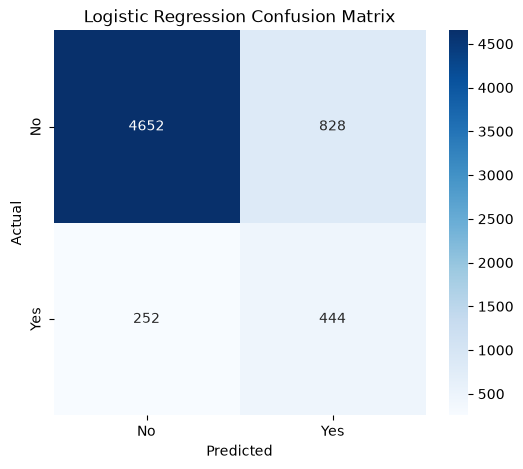

In [23]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_val, lr_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Logistic Regression Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

In [24]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

random_forest_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [25]:
rf_pred = random_forest_model.predict(X_val)
rf_prob = random_forest_model.predict_proba(X_val)[:, 1]

print("Random Forest Results")
print("---------------------")

print("Accuracy:", round(accuracy_score(y_val, rf_pred), 4))
print("Precision:", round(precision_score(y_val, rf_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, rf_pred), 4))
print("F1-score:", round(f1_score(y_val, rf_pred), 4))
print("PR-AUC:", round(average_precision_score(y_val, rf_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, rf_pred))

Random Forest Results
---------------------
Accuracy: 0.8722
Precision: 0.4337
Recall: 0.4368
F1-score: 0.4352
PR-AUC: 0.3881

Confusion Matrix:
[[5083  397]
 [ 392  304]]


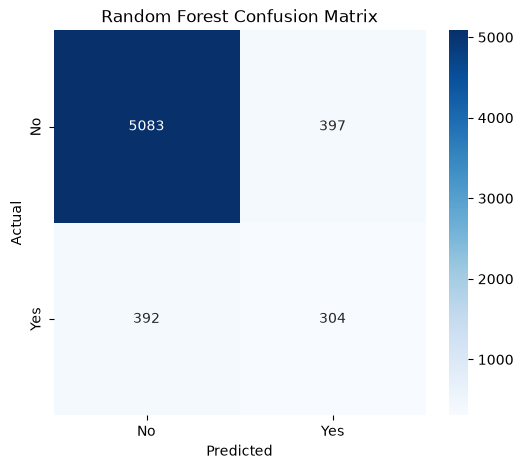

In [26]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_val, rf_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Random Forest Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

In [27]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.pipeline import Pipeline

gradient_boosting_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gradient_boosting_model.fit(X_train, y_train)

print("Gradient Boosting trained successfully!")

Gradient Boosting trained successfully!


In [28]:
gb_pred = gradient_boosting_model.predict(X_val)
gb_prob = gradient_boosting_model.predict_proba(X_val)[:, 1]

print("Gradient Boosting Results")
print("-------------------------")

print("Accuracy:", round(accuracy_score(y_val, gb_pred), 4))
print("Precision:", round(precision_score(y_val, gb_pred, zero_division=0), 4))
print("Recall:", round(recall_score(y_val, gb_pred), 4))
print("F1-score:", round(f1_score(y_val, gb_pred), 4))
print("PR-AUC:", round(average_precision_score(y_val, gb_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, gb_pred))

Gradient Boosting Results
-------------------------
Accuracy: 0.9011
Precision: 0.684
Recall: 0.227
F1-score: 0.3409
PR-AUC: 0.4709

Confusion Matrix:
[[5407   73]
 [ 538  158]]


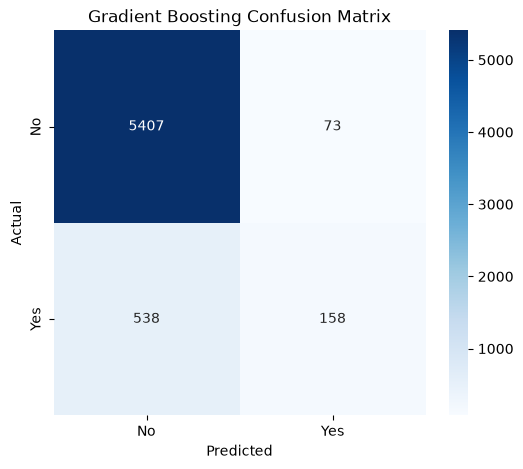

In [29]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_val, gb_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Gradient Boosting Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

---

## 5. Model Comparison and Optimization

### 5.1 Initial Model Comparison

The initial validation results demonstrate different tradeoffs
between precision and recall.

| Model | F1-score | PR-AUC |
|---|---:|---:|
| Baseline | 0.0000 | 0.1127 |
| Logistic Regression | 0.4512 | 0.4430 |
| Random Forest | 0.4352 | 0.3881 |
| Gradient Boosting | 0.3409 | 0.4709 |

**Key Observations**

- Logistic Regression achieved the highest initial F1-score.
- Gradient Boosting achieved the highest average precision.
- Random Forest provided relatively balanced precision and recall.

### 5.2 Hyperparameter Tuning

RandomizedSearchCV with three-fold stratified cross-validation
was used to optimize Gradient Boosting.

The tuned model did not outperform the original configuration
on the validation dataset.

### 5.3 Decision Threshold Optimization

The classification threshold was optimized using validation data
to maximize F1-score.

**Selected threshold:** `0.1857`

**Optimized validation F1-score:** `0.5056`

> **Interpretation:** Reducing the decision threshold improved
> subscriber detection while increasing false-positive predictions.

In [30]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)

models = {
    "Baseline": baseline,
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model,
    "Gradient Boosting": gradient_boosting_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_val)
    probabilities = model.predict_proba(X_val)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Precision": precision_score(y_val, predictions, zero_division=0),
        "Recall": recall_score(y_val, predictions),
        "F1-score": f1_score(y_val, predictions),
        "PR-AUC": average_precision_score(y_val, probabilities)
    })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score,PR-AUC
0,Baseline,0.8873,0.0000,0.0000,0.0000,0.1127
1,Logistic Regression,0.8251,0.3491,0.6379,0.4512,0.4430
2,Random Forest,0.8722,0.4337,0.4368,0.4352,0.3881
3,Gradient Boosting,0.9011,0.6840,0.2270,0.3409,0.4709


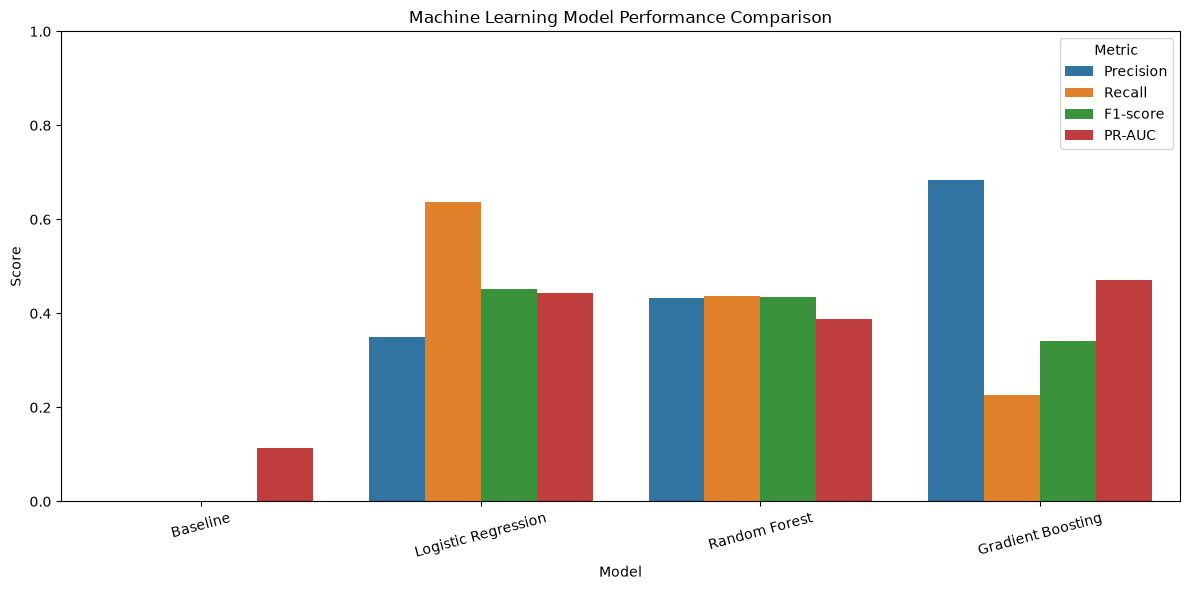

In [31]:
metrics_to_plot = ["Precision", "Recall", "F1-score", "PR-AUC"]

plot_df = results_df.melt(
    id_vars="Model",
    value_vars=metrics_to_plot,
    var_name="Metric",
    value_name="Score"
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=plot_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.title("Machine Learning Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Model")
plt.ylim(0, 1)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [32]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.base import clone

# Cross-validation strategy
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Hyperparameter search space
param_distributions = {
    "classifier__n_estimators": [100, 150, 200],
    "classifier__learning_rate": [0.03, 0.05, 0.1],
    "classifier__max_depth": [2, 3, 4],
    "classifier__min_samples_leaf": [10, 20, 40]
}

gb_search = RandomizedSearchCV(
    estimator=clone(gradient_boosting_model),
    param_distributions=param_distributions,
    n_iter=10,
    scoring="average_precision",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

gb_search.fit(X_train, y_train)

print("Best parameters:")
print(gb_search.best_params_)

print("\nBest cross-validation PR-AUC:",
      round(gb_search.best_score_, 4))

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters:
{'classifier__n_estimators': 100, 'classifier__min_samples_leaf': 10, 'classifier__max_depth': 4, 'classifier__learning_rate': 0.03}

Best cross-validation PR-AUC: 0.4579


In [33]:
# Retrieve best model
gb_tuned = gb_search.best_estimator_

# Predictions on validation data
gb_tuned_pred = gb_tuned.predict(X_val)
gb_tuned_prob = gb_tuned.predict_proba(X_val)[:, 1]

print("Tuned Gradient Boosting Results")
print("--------------------------------")

print("Accuracy:",
      round(accuracy_score(y_val, gb_tuned_pred), 4))

print("Precision:",
      round(precision_score(y_val, gb_tuned_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_val, gb_tuned_pred), 4))

print("F1-score:",
      round(f1_score(y_val, gb_tuned_pred), 4))

print("PR-AUC:",
      round(average_precision_score(y_val, gb_tuned_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, gb_tuned_pred))

Tuned Gradient Boosting Results
--------------------------------
Accuracy: 0.9011
Precision: 0.7114
Recall: 0.2055
F1-score: 0.3188
PR-AUC: 0.4627

Confusion Matrix:
[[5422   58]
 [ 553  143]]


In [34]:
import numpy as np
from sklearn.metrics import precision_recall_curve

# Use tuned Gradient Boosting probabilities
precision, recall, thresholds = precision_recall_curve(
    y_val, gb_tuned_prob
)

# Calculate F1 for each available threshold
f1_scores = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-10)
)

best_index = np.argmax(f1_scores)
best_threshold = thresholds[best_index]

print("Best threshold:", round(best_threshold, 4))
print("Best F1-score:", round(f1_scores[best_index], 4))
print("Precision:", round(precision[best_index], 4))
print("Recall:", round(recall[best_index], 4))

Best threshold: 0.1741
Best F1-score: 0.505
Precision: 0.446
Recall: 0.5819


In [35]:
# Apply optimized threshold
gb_optimized_pred = (
    gb_tuned_prob >= best_threshold
).astype(int)

print("Optimized Gradient Boosting Results")
print("-----------------------------------")

print("Accuracy:",
      round(accuracy_score(y_val, gb_optimized_pred), 4))

print("Precision:",
      round(precision_score(y_val, gb_optimized_pred), 4))

print("Recall:",
      round(recall_score(y_val, gb_optimized_pred), 4))

print("F1-score:",
      round(f1_score(y_val, gb_optimized_pred), 4))

print("PR-AUC:",
      round(average_precision_score(y_val, gb_tuned_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, gb_optimized_pred))

Optimized Gradient Boosting Results
-----------------------------------
Accuracy: 0.8714
Precision: 0.446
Recall: 0.5819
F1-score: 0.505
PR-AUC: 0.4627

Confusion Matrix:
[[4977  503]
 [ 291  405]]


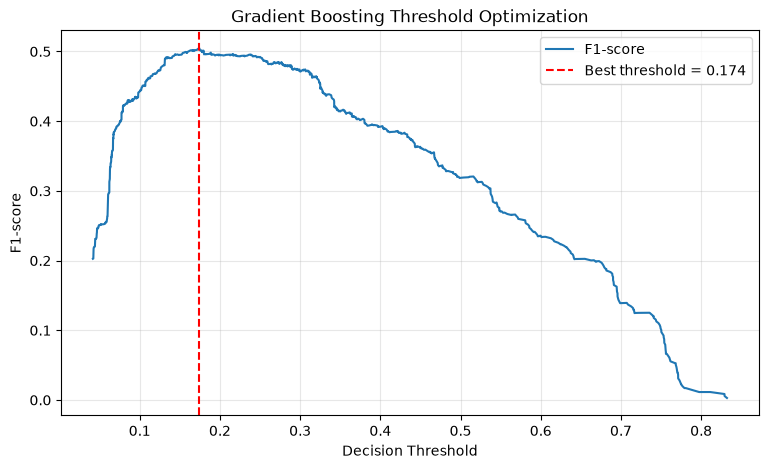

In [36]:
plt.figure(figsize=(9, 5))

plt.plot(thresholds, f1_scores, label="F1-score")

plt.axvline(
    best_threshold,
    color="red",
    linestyle="--",
    label=f"Best threshold = {best_threshold:.3f}"
)

plt.xlabel("Decision Threshold")
plt.ylabel("F1-score")
plt.title("Gradient Boosting Threshold Optimization")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

In [37]:
# Optimize threshold for original Gradient Boosting
precision_orig, recall_orig, thresholds_orig = precision_recall_curve(
    y_val, gb_prob
)

f1_orig = (
    2 * precision_orig[:-1] * recall_orig[:-1] /
    (precision_orig[:-1] + recall_orig[:-1] + 1e-10)
)

best_idx_orig = np.argmax(f1_orig)
best_threshold_orig = thresholds_orig[best_idx_orig]

gb_original_optimized_pred = (
    gb_prob >= best_threshold_orig
).astype(int)

print("Original Gradient Boosting - Optimized Threshold")
print("Threshold:", round(best_threshold_orig, 4))
print("Precision:", round(precision_score(y_val, gb_original_optimized_pred), 4))
print("Recall:", round(recall_score(y_val, gb_original_optimized_pred), 4))
print("F1-score:", round(f1_score(y_val, gb_original_optimized_pred), 4))
print("PR-AUC:", round(average_precision_score(y_val, gb_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_val, gb_original_optimized_pred))

Original Gradient Boosting - Optimized Threshold
Threshold: 0.1857
Precision: 0.447
Recall: 0.5819
F1-score: 0.5056
PR-AUC: 0.4709

Confusion Matrix:
[[4979  501]
 [ 291  405]]


---

## 6. Information Leakage Experiment

### 6.1 Experimental Objective

The `duration` feature records the length of a marketing call.

Because this information is unavailable before a call occurs,
including it would introduce information leakage for pre-call
subscription prediction.

### 6.2 Experimental Results

| Feature Configuration | Validation PR-AUC |
|---|---:|
| Without duration | 0.4709 |
| With duration | 0.6551 |

Including duration increased average precision by **0.1842**,
representing approximately a **39.1% relative improvement**.

> **Key Finding:** The experiment demonstrates how including
> information unavailable at prediction time can inflate apparent
> model performance. The final model therefore excludes `duration`.

In [38]:
# Include duration for the leakage experiment
X_with_duration = df_clean.drop(columns=["y"])

# Use the same train/validation indices as before
X_train_duration = X_with_duration.loc[X_train.index]
X_val_duration = X_with_duration.loc[X_val.index]

print("Without duration:", X_train.shape)
print("With duration:", X_train_duration.shape)

Without duration: (28823, 19)
With duration: (28823, 20)


In [39]:
from sklearn.base import clone

# Add duration to the numerical features
numerical_features_duration = numerical_features + ["duration"]

preprocessor_duration = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_features_duration),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Create model with duration included
gb_with_duration = Pipeline(steps=[
    ("preprocessor", preprocessor_duration),
    ("classifier", GradientBoostingClassifier(
        n_estimators=100,
        learning_rate=0.1,
        max_depth=3,
        random_state=42
    ))
])

gb_with_duration.fit(X_train_duration, y_train)

print("Gradient Boosting with duration trained successfully!")

Gradient Boosting with duration trained successfully!


In [40]:
# Predictions with duration
duration_prob = gb_with_duration.predict_proba(
    X_val_duration
)[:, 1]

# Compare PR-AUC
pr_auc_without = average_precision_score(y_val, gb_prob)
pr_auc_with = average_precision_score(y_val, duration_prob)

print("Information Leakage Experiment")
print("------------------------------")
print("PR-AUC without duration:", round(pr_auc_without, 4))
print("PR-AUC with duration:", round(pr_auc_with, 4))
print("Difference:", round(pr_auc_with - pr_auc_without, 4))

Information Leakage Experiment
------------------------------
PR-AUC without duration: 0.4709
PR-AUC with duration: 0.6551
Difference: 0.1842


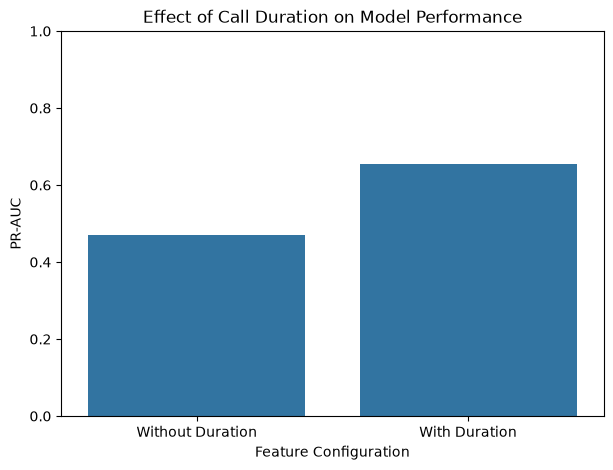

In [41]:
plt.figure(figsize=(7, 5))

sns.barplot(
    x=["Without Duration", "With Duration"],
    y=[pr_auc_without, pr_auc_with]
)

plt.title("Effect of Call Duration on Model Performance")
plt.ylabel("PR-AUC")
plt.xlabel("Feature Configuration")
plt.ylim(0, 1)

plt.show()

---

## 7. Final Model Evaluation

The selected Gradient Boosting classifier was evaluated on the
previously untouched test dataset.

### 7.1 Test Performance

| Metric | Score |
|---|---:|
| Accuracy | 0.8813 |
| Precision | 0.4789 |
| Recall | 0.6034 |
| F1-score | 0.5340 |
| PR-AUC | 0.4896 |

### 7.2 Interpretation

The final model correctly identified **420 of 696 subscribers**
in the test dataset.

Although the model produced 457 false-positive predictions,
it achieved substantially better subscriber detection than
the majority-class baseline.

The test results were consistent with validation performance,
suggesting reasonable generalization to unseen observations.

In [42]:
# Predict probabilities on the test dataset
test_prob = gradient_boosting_model.predict_proba(X_test)[:, 1]

# Apply the selected validation threshold
test_pred = (test_prob >= best_threshold_orig).astype(int)

print("Final Gradient Boosting Test Results")
print("------------------------------------")

print("Accuracy:",
      round(accuracy_score(y_test, test_pred), 4))

print("Precision:",
      round(precision_score(y_test, test_pred, zero_division=0), 4))

print("Recall:",
      round(recall_score(y_test, test_pred), 4))

print("F1-score:",
      round(f1_score(y_test, test_pred), 4))

print("PR-AUC:",
      round(average_precision_score(y_test, test_prob), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, test_pred))

Final Gradient Boosting Test Results
------------------------------------
Accuracy: 0.8813
Precision: 0.4789
Recall: 0.6034
F1-score: 0.534
PR-AUC: 0.4896

Confusion Matrix:
[[5024  457]
 [ 276  420]]


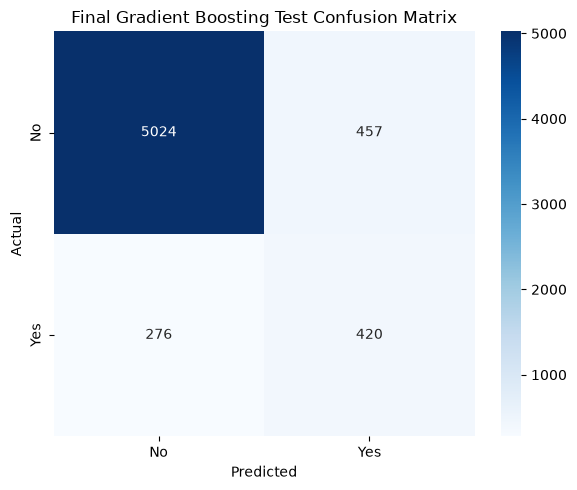

In [43]:
plt.figure(figsize=(6, 5))

sns.heatmap(
    confusion_matrix(y_test, test_pred),
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No", "Yes"],
    yticklabels=["No", "Yes"]
)

plt.title("Final Gradient Boosting Test Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.tight_layout()
plt.show()

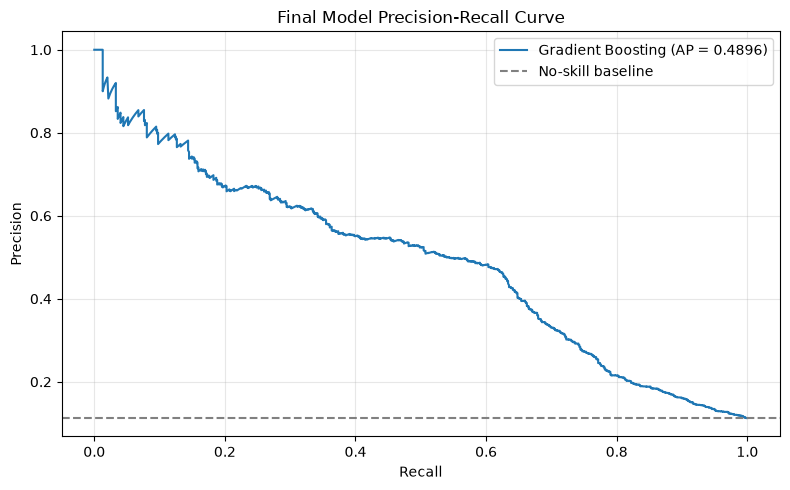

In [44]:
from sklearn.metrics import precision_recall_curve

test_precision, test_recall, _ = precision_recall_curve(
    y_test, test_prob
)

plt.figure(figsize=(8, 5))

plt.plot(
    test_recall,
    test_precision,
    label=f"Gradient Boosting (AP = {average_precision_score(y_test, test_prob):.4f})"
)

plt.axhline(
    y=y_test.mean(),
    color="gray",
    linestyle="--",
    label="No-skill baseline"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Final Model Precision-Recall Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

---

## 8. Model Saving and Prediction Demonstration

### 8.1 Model Persistence

The selected Gradient Boosting pipeline was saved using Joblib.

The saved artifact includes:

- Trained preprocessing and classification pipeline
- Optimized classification threshold
- Expected input feature names

### 8.2 Single-Customer Prediction

A customer from the held-out test dataset was used to demonstrate
the prediction workflow.

| Output | Value |
|---|---|
| Estimated subscription probability | 3.88% |
| Classification threshold | 18.57% |
| Predicted outcome | No |

Because the estimated probability is below the decision threshold,
the customer is classified as unlikely to subscribe.

In [50]:
import joblib
from pathlib import Path

model_dir = Path("../models")
model_dir.mkdir(parents=True, exist_ok=True)

# Save the trained pipeline and threshold together
model_artifact = {
    "model": gradient_boosting_model,
    "threshold": float(best_threshold_orig),
    "features": X_train.columns.tolist()
}

model_path = model_dir / "bank_subscription_model.joblib"

joblib.dump(model_artifact, model_path)

print("Model saved successfully!")
print("Location:", model_path)
print("Threshold:", model_artifact["threshold"])

Model saved successfully!
Location: ../models/bank_subscription_model.joblib
Threshold: 0.1856910427273074


In [51]:
# Load saved model
loaded_artifact = joblib.load(model_path)

loaded_model = loaded_artifact["model"]
loaded_threshold = loaded_artifact["threshold"]

# Verify predictions match the original model
loaded_prob = loaded_model.predict_proba(X_test)[:, 1]

print("Model loaded successfully!")
print("Predictions match:",
      np.allclose(test_prob, loaded_prob))
print("Loaded threshold:", loaded_threshold)

Model loaded successfully!
Predictions match: True
Loaded threshold: 0.1856910427273074


In [52]:
# Select one customer from the test dataset
customer = X_test.iloc[[0]]

# Predict subscription probability
customer_probability = loaded_model.predict_proba(customer)[0, 1]

# Apply optimized decision threshold
customer_prediction = int(
    customer_probability >= loaded_threshold
)

print("Single Customer Prediction")
print("--------------------------")

print("Subscription probability:",
      round(customer_probability, 4))

print("Predicted outcome:",
      "Yes" if customer_prediction == 1 else "No")

print("Decision threshold:",
      round(loaded_threshold, 4))

Single Customer Prediction
--------------------------
Subscription probability: 0.0388
Predicted outcome: No
Decision threshold: 0.1857


In [53]:
print("Customer Information")
print("--------------------")

display(customer.T)

Customer Information
--------------------


,8122
age,36
job,technician
marital,divorced
education,professional.course
default,unknown
housing,no
loan,no
contact,telephone
month,jun
day_of_week,mon


---

## 9. Conclusion and Key Findings

This project demonstrated the application of supervised machine
learning to an imbalanced bank marketing classification problem.

### Key Findings

1. **Class imbalance matters:** Accuracy alone did not adequately
   represent model effectiveness.

2. **Model selection requires multiple metrics:** Different
   classifiers exhibited different precision-recall tradeoffs.

3. **Threshold optimization improved classification:** Gradient
   Boosting achieved a validation F1-score of 0.5056 after
   threshold adjustment.

4. **Information leakage affects evaluation:** Including call
   duration substantially increased apparent predictive performance.

5. **The final model generalized reasonably well:** The selected
   classifier achieved a test F1-score of 0.5340 and PR-AUC of 0.4896.

### Limitations

The model uses historical campaign data, produces false-positive
predictions, and has not been evaluated under changing real-world
market conditions.

### Final Outcome

The project successfully developed and evaluated a reproducible
machine learning pipeline for identifying potential term deposit
subscribers.